# Example of the aitlas toolbox in the context of object detection in remote sensing images

## Import the required packages

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning) 
warnings.filterwarnings("ignore", category=DeprecationWarning) 

import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import AirbusOilStorageDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN
import csv 

## Visualize images and objects witn bounding boxes

Total number of patches: 98


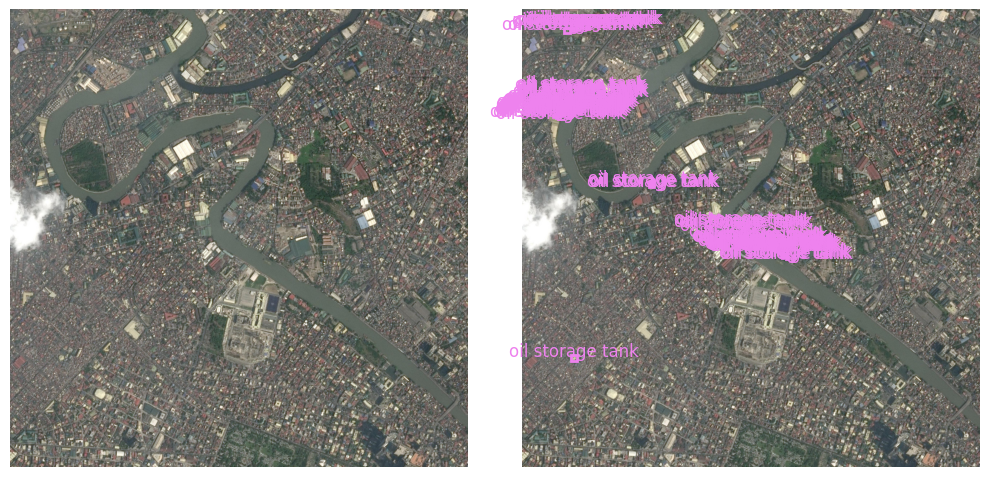

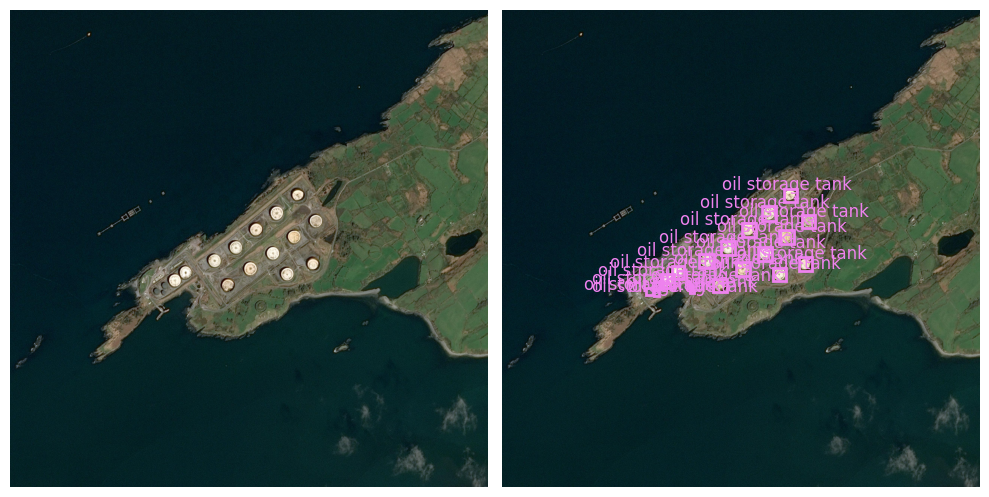

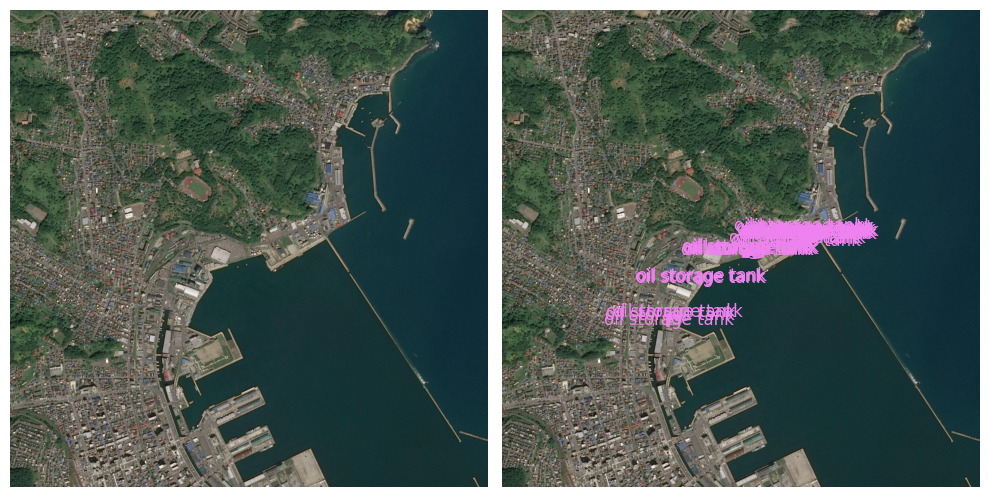

In [ ]:
dataset_config = {
    "data_dir": "./data/airbus_oil_storage/images/",
    "annotation_dir": "./data/airbus_oil_storage/annotations.csv",
}
dataset = AirbusOilStorageDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(10);
dataset.show_image(90);

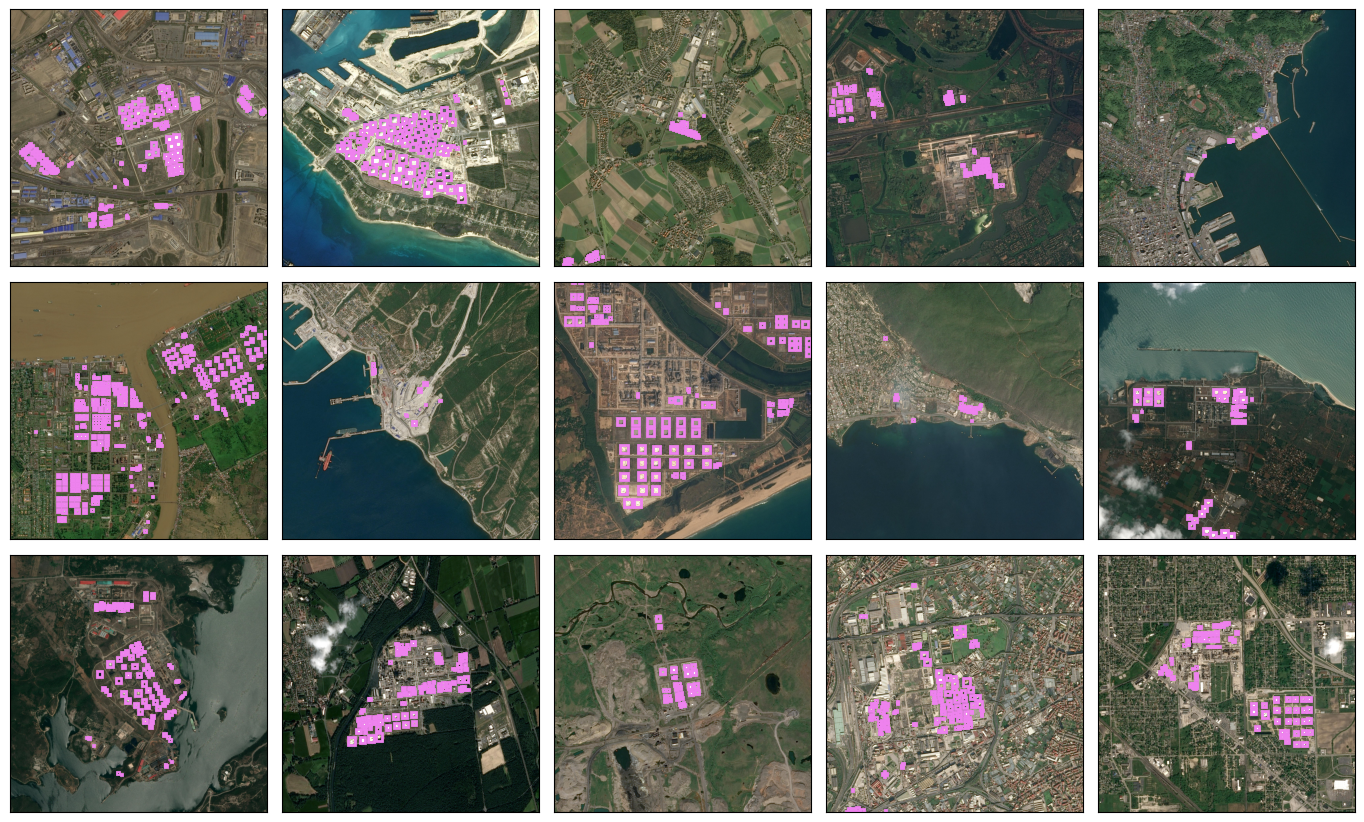

In [9]:
dataset.show_batch(15);

In [13]:
dataset.data_distribution_table()

,Label,Count
0,oil storage tank,13590


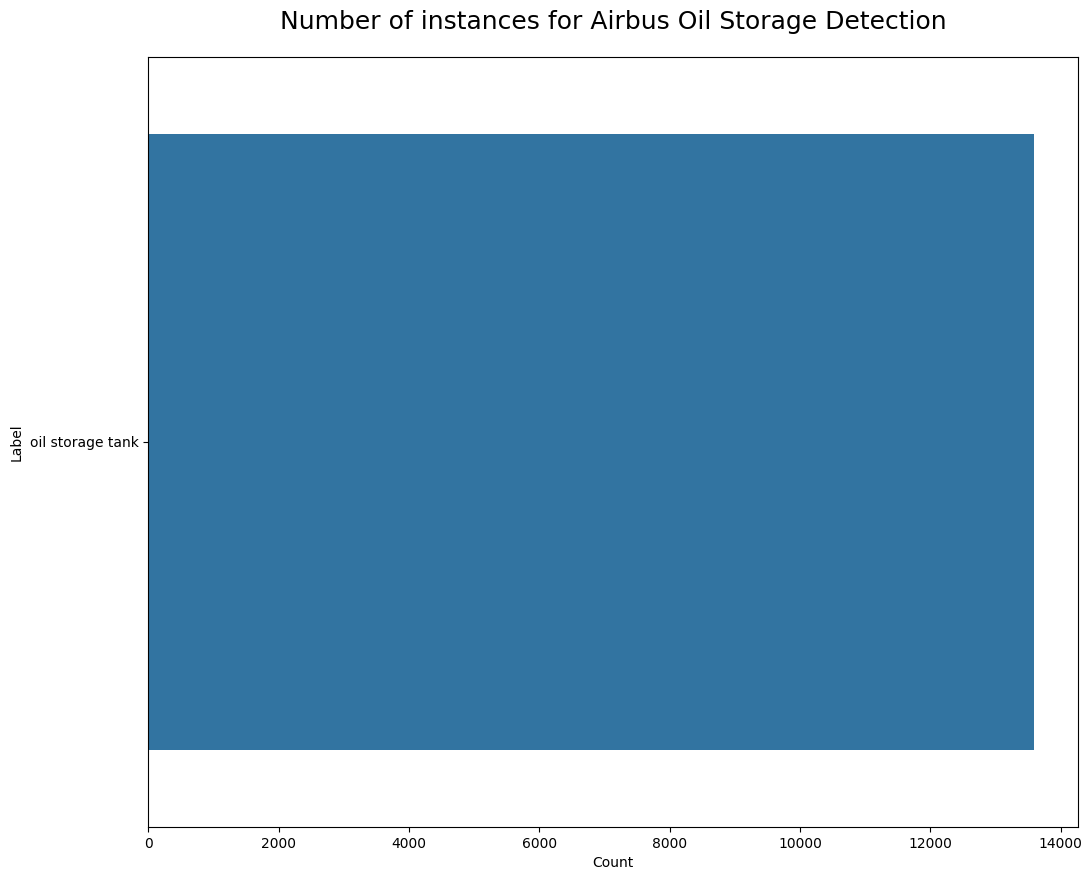

In [14]:
dataset.data_distribution_barchart();

## Load train data

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "data_dir": "./data/airbus_oil_storage/images/",
    "annotation_dir": "./data/airbus_oil_storage/annotations.csv",
    "csv_file": "./data/airbus_oil_storage/train.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = AirbusOilStorageDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 79


## Create the model

In [ ]:
epochs = 10
model_directory = "./data/airbus_oil_storage/experiments/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [36]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-05-21 13:32:56,879 INFO Starting training.
training: 100%|██████████| 10/10 [00:15<00:00,  1.53s/it]
2025-05-21 13:33:12,741 INFO epoch: 1, time: 15, loss:  2.88647
testing on train set: 100%|██████████| 10/10 [00:10<00:00,  1.02s/it]
2025-05-21 13:33:40,568 INFO map:0.05091268941760063, map_50:0.14919178187847137, map_75:0.021694470196962357, map_small:0.05091268941760063, map_medium:-1.0, map_large:-1.0, mar_1:0.003339882008731365, mar_10:0.026700345799326897, mar_100:0.0708017572760582, mar_small:0.0708017572760582, mar_medium:-1.0, mar_large:-1.0, map_per_class:0.05091268941760063, mar_100_per_class:0.0708017572760582, classes:1.0
training: 100%|██████████| 10/10 [00:15<00:00,  1.60s/it]
2025-05-21 13:33:56,571 INFO epoch: 2, time: 16, loss:  1.16068
testing on train set: 100%|██████████| 10/10 [00:09<00:00,  1.09it/s]
2025-05-21 13:34:25,367 INFO map:0.10965467989444733, map_50:0.20979346334934235, map_75:0.10624430328607559, map_small:0.10965467989444733, map_medium:-1.0, ma

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "./data/airbus_oil_storage/images/",
    "annotation_dir": "./data/airbus_oil_storage/annotations.csv",
    "csv_file": "./data/airbus_oil_storage/val.csv",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = AirbusOilStorageDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/airbus_oil_storage/experiments/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 9


2025-05-21 13:41:18,535 INFO Loading checkpoint /home/dragik/data/FAIR_EO/airbus_oil_storage/experiments/checkpoint.pth.tar
2025-05-21 13:41:20,243 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/airbus_oil_storage/experiments/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 2/2 [00:02<00:00,  1.48s/it]


[{'map': 0.14940960705280304,
  'map_50': 0.24082471430301666,
  'map_75': 0.16741938889026642,
  'map_small': 0.14940960705280304,
  'map_medium': -1.0,
  'map_large': -1.0,
  'mar_1': 0.003997461870312691,
  'mar_10': 0.03604060783982277,
  'mar_100': 0.16288070380687714,
  'mar_small': 0.16288070380687714,
  'mar_medium': -1.0,
  'mar_large': -1.0,
  'map_per_class': 0.14940960705280304,
  'mar_100_per_class': 0.16288070380687714,
  'classes': 1.0}]

## Predictions

2025-05-21 13:41:39,312 INFO Loading checkpoint /home/dragik/data/FAIR_EO/airbus_oil_storage/experiments/checkpoint.pth.tar
2025-05-21 13:41:40,975 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/airbus_oil_storage/experiments/checkpoint.pth.tar at epoch 11


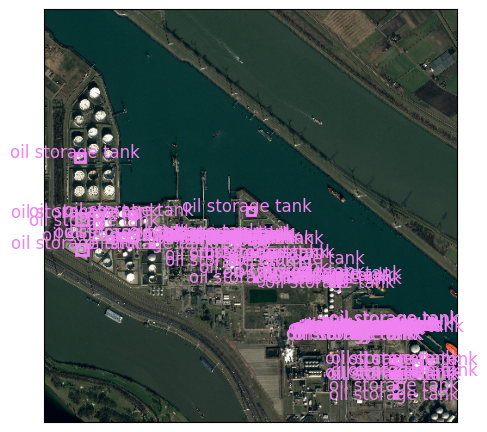

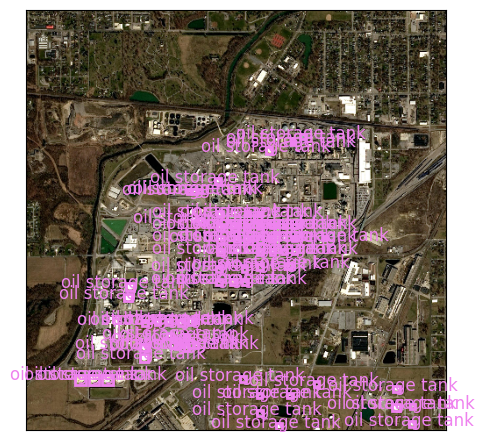

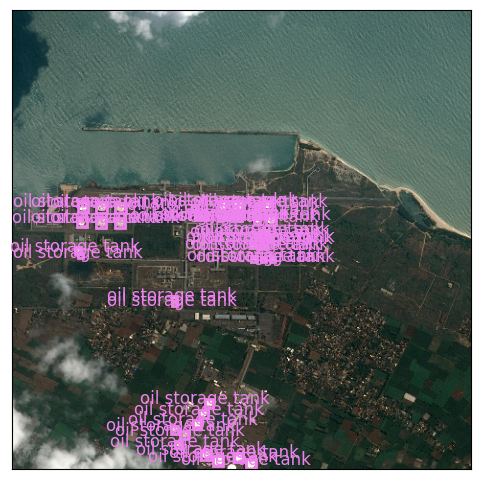

In [ ]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "./data/airbus_oil_storage/experiments/checkpoint.pth.tar"
labels = ["no-data", "oil storage tank"]
transform = Resize()
model.load_model(model_path)

csv_file = "./data/airbus_oil_storage/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/airbus_oil_storage/' + test_list[0])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/airbus_oil_storage/' + test_list[5])
fig = model.detect_objects(image, labels, transform)

image = image_loader('./data/airbus_oil_storage/' + test_list[7])
fig = model.detect_objects(image, labels, transform)